# Tc_Fe_real

- $A_{bulk} = 2.1\times10^{-11}$ J/m (constante de rigidez de intercambio)
- $a = 0.287$ nm (constante de red real del Fe bcc, usada como tamano de celda)
- $M_s = 1.7\times10^6$ A/m

**`n_repeats=5`** -- cinco simulaciones independientes por temperatura (cada una con su propia semilla), promediadas con su error estandar. Con 5 repeticiones, el barrido completo (40 temperaturas) toma aproximadamente 1.5 horas.

In [8]:
import time
import numpy as np
import matplotlib.pyplot as plt
import discretisedfield as df
import micromagneticmodel as mm
import oommfc as mc
from scipy.optimize import curve_fit

In [ ]:
A_bulk = 2.1e-11       # J/m, constante de intercambio real del Fe (bulk)
Ms_Fe = 1.7e6          # A/m, magnetizacion de saturacion real del Fe
a = 0.287e-9           # m, constante de red real del Fe (bcc) -- celda atomica real
alpha = 0.1            # amortiguamiento de Gilbert
gamma0 = mm.consts.gamma0
Tc_exp = 1043.0        # K, solo para comparar al final

N = 8                   # celdas (atomos) por lado -> muestra de 8*0.287 = 2.3 nm
L = N * a
mesh = df.Mesh(p1=(0, 0, 0), p2=(L, L, L), cell=(a, a, a), bc="xyz")  # fronteras periodicas
print("malla:", mesh.n, "->", np.prod(mesh.n), "celdas (atomos), bc =", mesh.bc)
print(f"tamano fisico de la muestra: {L*1e9:.2f} nm por lado")

malla: [8 8 8] -> 512 celdas (atomos), bc = xyz
tamano fisico de la muestra: 2.30 nm por lado


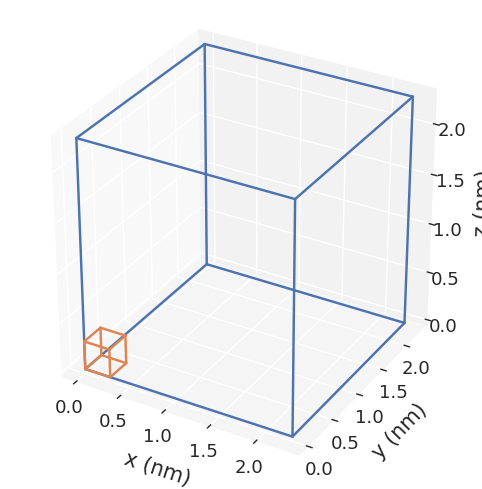

In [10]:
mesh.mpl()

In [ ]:
dt = 2e-16              # s, paso de tiempo
total_steps = 100000    # 100,000 * 2e-16 s = 20 ps de tiempo fisico simulado por punto
n_stages = 10           # se promedia la segunda mitad (10 ps) como parte de la termalizacion
n_repeats = 5           # corridas independientes por temperatura (distinta semilla c/u)

Ts = list(range(10, 2001, 50))   # 40 temperaturas
means = []
sems = []

t_start = time.time()
for i, T in enumerate(Ts):
    vals = []
    for r in range(n_repeats):
        system = mm.System(name=f"Fe_real_{i}_{r}")
        system.m = df.Field(mesh, nvdim=3, value=(1, 0, 0), norm=Ms_Fe)
        system.energy = mm.Exchange(A=A_bulk)
        system.dynamics = mm.Damping(alpha=alpha) + mm.Precession(gamma0=gamma0)
        system.T = T

        # semilla distinta en cada corrida: sin esto, UHH_ThetaEvolver reusa el mismo
        # ruido termico por defecto y las "repeticiones" saldrian identicas.
        seed = i * n_repeats + r + 1
        evolver = mc.UHH_ThetaEvolver(fixed_timestep=dt, uniform_seed=seed)
        td = mc.TimeDriver(evolver=evolver)
        td.drive(system, t=dt * total_steps, n=n_stages, verbose=0)

        equilibrado = system.table.data.iloc[n_stages // 2:]
        m_mean = equilibrado[["mx", "my", "mz"]].mean().to_numpy()
        vals.append(np.linalg.norm(m_mean))

    vals = np.array(vals)
    means.append(vals.mean())
    sems.append(vals.std(ddof=1) / np.sqrt(n_repeats))  # error estandar de la media
    print(f"T = {T:5d} K   <m> = {means[-1]:.4f} +/- {sems[-1]:.4f}   "
          f"({time.time()-t_start:6.1f} s acumulado)")

means = np.array(means)
sems = np.array(sems)
orders = means  # alias, por compatibilidad con las celdas de abajo

T =    10 K   <m> = 0.9963 +/- 0.0001   ( 128.3 s acumulado)
T =    60 K   <m> = 0.9769 +/- 0.0007   ( 258.1 s acumulado)
T =   110 K   <m> = 0.9591 +/- 0.0008   ( 385.1 s acumulado)
T =   160 K   <m> = 0.9410 +/- 0.0011   ( 514.0 s acumulado)
T =   210 K   <m> = 0.9204 +/- 0.0019   ( 639.0 s acumulado)
T =   260 K   <m> = 0.9053 +/- 0.0016   ( 768.1 s acumulado)
T =   310 K   <m> = 0.8812 +/- 0.0044   ( 897.2 s acumulado)
T =   360 K   <m> = 0.8579 +/- 0.0047   (1024.6 s acumulado)
T =   410 K   <m> = 0.8435 +/- 0.0063   (1154.8 s acumulado)
T =   460 K   <m> = 0.8278 +/- 0.0030   (1282.2 s acumulado)
T =   510 K   <m> = 0.8010 +/- 0.0056   (1406.3 s acumulado)
T =   560 K   <m> = 0.7790 +/- 0.0034   (1534.2 s acumulado)
T =   610 K   <m> = 0.7594 +/- 0.0020   (1657.5 s acumulado)
T =   660 K   <m> = 0.7345 +/- 0.0108   (1785.9 s acumulado)
T =   710 K   <m> = 0.7039 +/- 0.0051   (1913.7 s acumulado)
T =   760 K   <m> = 0.6990 +/- 0.0061   (2038.6 s acumulado)
T =   810 K   <m> = 0.65

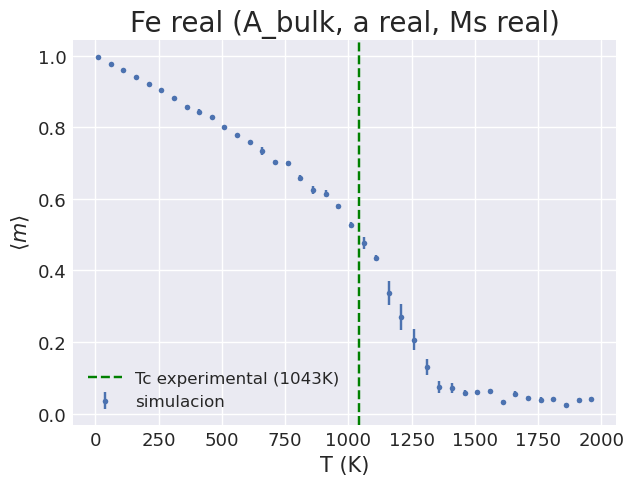

In [29]:
plt.figure(figsize=(7, 5))
plt.errorbar(Ts, means, yerr=sems, fmt="o", ms=4, capsize=3,
             label=f"simulacion")
plt.axvline(Tc_exp, color="g", ls="--", label=f"Tc experimental ({Tc_exp:.0f}K)")
plt.xlabel("T (K)")
plt.ylabel(r"$\langle m \rangle$")
plt.title("Fe real (A_bulk, a real, Ms real)")
plt.legend()
plt.grid(True)
plt.show()

## Estimacion del punto de inflexion

Ajustamos una sigmoide $\langle m\rangle(T)=\frac{m_0}{1+e^{(T-T_c)/w}}+c$ y leemos $T_c$ del ajuste, ponderando cada punto por su error estandar real (`sigma=sems, absolute_sigma=True`) en vez de dejar que `curve_fit` lo adivine del residuo.

Tc simulado = 973 +/- 6 K
Tc experimental del Fe = 1043 K
Diferencia relativa = 6.7 %


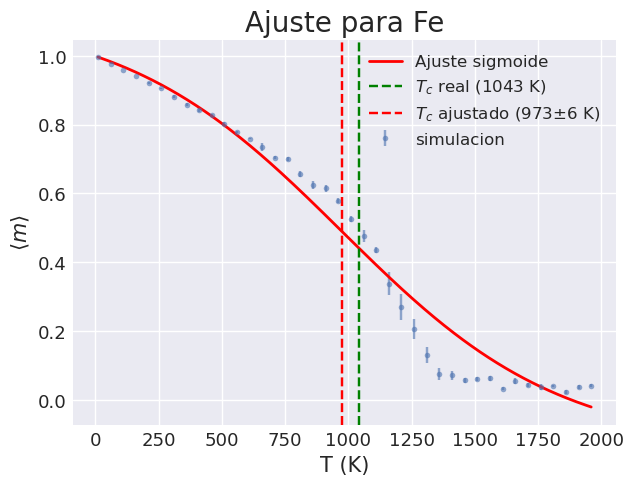

In [28]:
def sigmoide(T, m0, Tc, w, c):
    return m0 / (1 + np.exp((T - Tc) / w)) + c

Ts_arr = np.array(Ts, dtype=float)
p0 = [1.0, 1000, 150, means[-1]]
popt, pcov = curve_fit(sigmoide, Ts_arr, means, p0=p0, sigma=sems,
                        absolute_sigma=True, maxfev=20000)
perr = np.sqrt(np.diag(pcov))

Tc_fit, Tc_err = popt[1], perr[1]
print(f"Tc simulado = {Tc_fit:.0f} +/- {Tc_err:.0f} K")
print(f"Tc experimental del Fe = {Tc_exp:.0f} K")
print(f"Diferencia relativa = {100*(Tc_exp - Tc_fit)/Tc_exp:.1f} %")

Tfine = np.linspace(min(Ts_arr), max(Ts_arr), 400)
plt.figure(figsize=(7, 5))
plt.errorbar(Ts_arr, means, yerr=sems, fmt="o", ms=4, capsize=3, alpha=0.6,
             label=f"simulacion")
plt.plot(Tfine, sigmoide(Tfine, *popt), "r-", lw=2,
         label=f"Ajuste sigmoide")
plt.axvline(Tc_exp, color="g", ls="--", label=f"$T_c$ real ({Tc_exp:.0f} K)")
plt.axvline(Tc_fit, color="r", ls="--", label=f"$T_c$ ajustado ({Tc_fit:.0f}$\\pm${Tc_err:.0f} K)")
plt.xlabel("T (K)")
plt.ylabel(r"$\langle m \rangle$")
plt.title("Ajuste para Fe")
plt.legend()
plt.grid(True)
plt.show()